## **Lesson 5: Deploying ML Models**

#### Overview

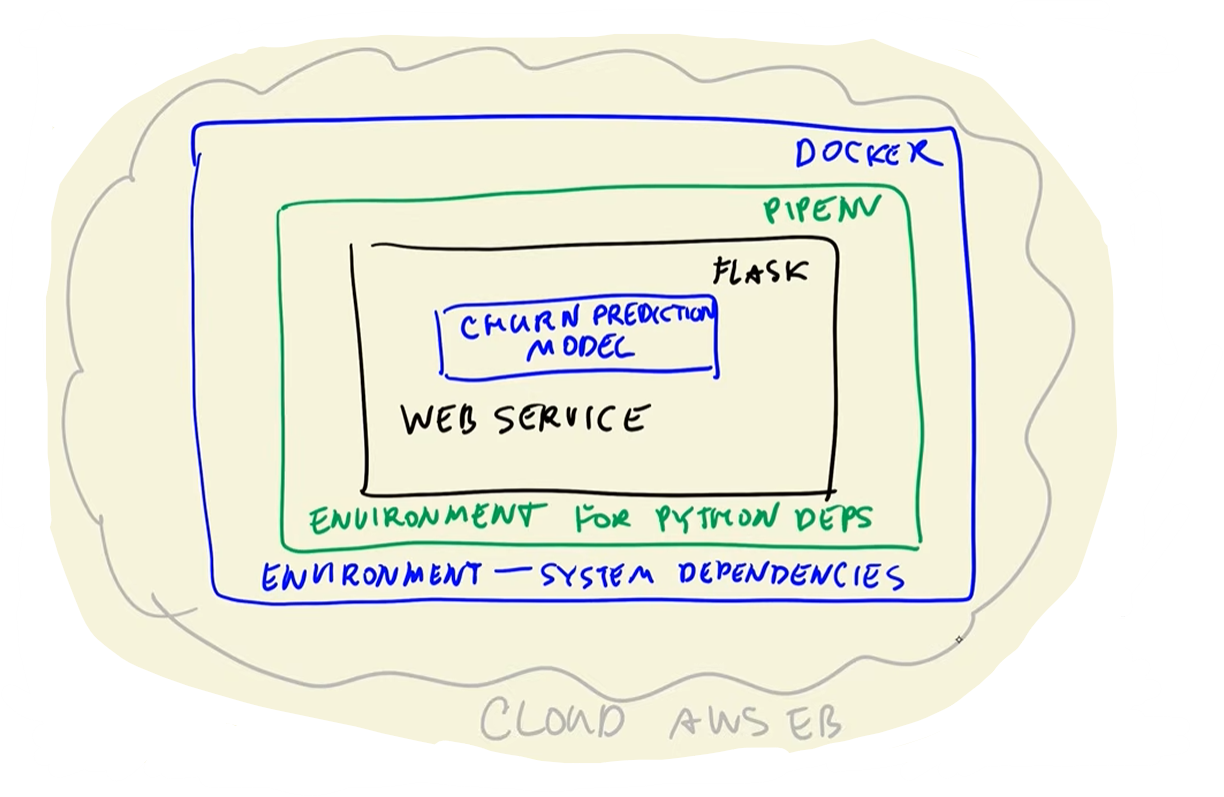

Model from lesson 4

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.model_selection import KFold

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv')

df.columns = df.columns.str.lower().str.replace(' ', '_')
categorical_columns = list(df.dtypes[df.dtypes == 'string'].index)

for col in categorical_columns:
    df[col] = df[col].str.lower().str.replace(' ', '_')

df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0) ## fill the NaN values with 0  

df.churn = (df.churn == 'yes').astype(int)


In [15]:
df_train_full, df_test = train_test_split(df, test_size=0.2, random_state=1)
y_test = df_test.churn.values

In [6]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']
categorical = ['gender', 'seniorcitizen', 'partner', 'dependents', 'phoneservice', 'multiplelines', 
               'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 
               'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod']

In [7]:
def train(df, y_train, C=1.0):

    dicts = df[categorical + numerical].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(C=C, max_iter=1000)
    model.fit(X_train, y_train, C)

    return dv, model

def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:,1]

    return y_pred

In [8]:
C = 1.0
n_splits = 5

In [12]:
kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_train_full):
    df_train = df_train_full.iloc[train_idx]
    df_val = df_train_full.iloc[val_idx]

    y_train = df_train.churn.values
    y_val = df_val.churn.values

    dv, model = train(df_train, y_train, C=C)
    y_pred = predict(df_val, dv, model)

    #print(len(y_val), len(y_pred))
    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

c:\Users\kenji\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\kenji\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please als

C=1.0 0.842 +- 0.007


c:\Users\kenji\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [13]:
scores

[0.8446397312212008,
 0.8452916004502715,
 0.8332972105157537,
 0.8347529097653003,
 0.8518206206269022]

In [16]:
dv, model = train(df_train_full, df_train_full.churn.values, C=1.0)
y_pred = predict(df_test, dv, model)

auc = roc_auc_score(y_test, y_pred)
auc

c:\Users\kenji\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.858525084771469

##### Save the model

In [17]:
import pickle

In [18]:
output_file = f'model_C={C}.bin'
output_file

'model_C=1.0.bin'

In [19]:
with open(output_file, 'wb') as f_out:
    pickle.dump((dv, model), f_out)

##### Load the model

In [6]:
import pickle

In [8]:
model_file = 'model_C=1.0.bin'

with open(model_file, 'rb') as f_in:
    dv, model = pickle.load(f_in)

In [9]:
dv, model

(DictVectorizer(sparse=False), LogisticRegression(max_iter=1000))

In [23]:
customer = {'gender':'female',
            'seniorcitizen': 0,
            'partner': 'yes',
            'dependents': 'no',
            'tenure': 20,
            'phoneservice': 'no',
            'multiplelines': 'no_phone_service',
            'internetservice': 'dsl',
            'onlinesecurity': 'no',
            'onlinebackup': 'yes',
            'deviceprotection': 'no',
            'techsupport': 'no',
            'streamingtv': 'no',
            'streamingmovies': 'no',
            'contract': 'month-to-month',
            'paperlessbilling': 'yes',
            'paymentmethod': 'electronic_check',
            'monthlycharges': 29.85,
            'totalcharges': 29.85}

In [24]:
X = dv.transform([customer])

In [25]:
model.predict_proba(X)[0, 1]

np.float64(0.34291881330526824)